rumz
# Notebook for processing layers in ice
### March 25
#### V. 1.1.2
- Updated to match spectralBubbles V. 1.1.2

This notebook processes hyperspectral images of ice and extracts information in regards to climate proxies.
To run:
- ensure datasetPath points to the correct directory file
- Insert DataID for whichever core to be run

In [1]:
import warnings
import sys
import os

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from icespec import savePNG
from icespec import ageConversion

### Users should fill in variables with desired core info
Use HSI_July2024 Spreadsheet for ID and section names

Debug variable prints more information during processing

In [2]:
datasetPath = '/data/icecores/HSI_2024.csv' #path to csv file on computer or server

outputDir = '/data/icecores/Output' #png output path

DataID = "HSIUM-171" #insert DataID from excel file inside quotation marks

Debug = False

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims = processice.getDataPath(datasetPath, DataID, outputDir)

outputPath = f"{save_path}/"
print("Output Path: ", outputPath)

%matplotlib ipympl
data_nparr, w_ref, d_ref, fwhm = processice.getEnviData(dataPath)

Core:  GISP2D
Section:  2088
Lighting: Top light - 75%, Bottom Light - 100%
Exposure:  10
Top Depth:  2087.21
Bottom Depth:  2087.36
Length =  0.15000000000009095
Dimensions:  1190, 2090, 100, 880
Output Path:  /data/icecores/Output/GL/GISP2/GISP2D/GISP2D-2088/


In [4]:
segment_boundaries, cm_per_pixel = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, end_px=px_dims[1])
print("cm per px: ", cm_per_pixel)

#dataSize = [1500, 6600, 200, 900] #fill in based on interactive plot
dataSize = px_dims
stdSize = [530, 820, 200, 900] #standard sizing

cm per px:  59.33333333329736


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 105, 106, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 148, 153, 195, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (900, 50, 224)
Shape After:  (900, 50, 100)
Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 72, 105, 106, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127,

/hsidata/hsiCode/stat/icespec/filter_bands_module.py:76: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (900, 50, 224)
Shape After:  (900, 50, 39)
Flattened shape:  (45000, 100)
Flattened shape:  (45000, 101)
Flattened sh

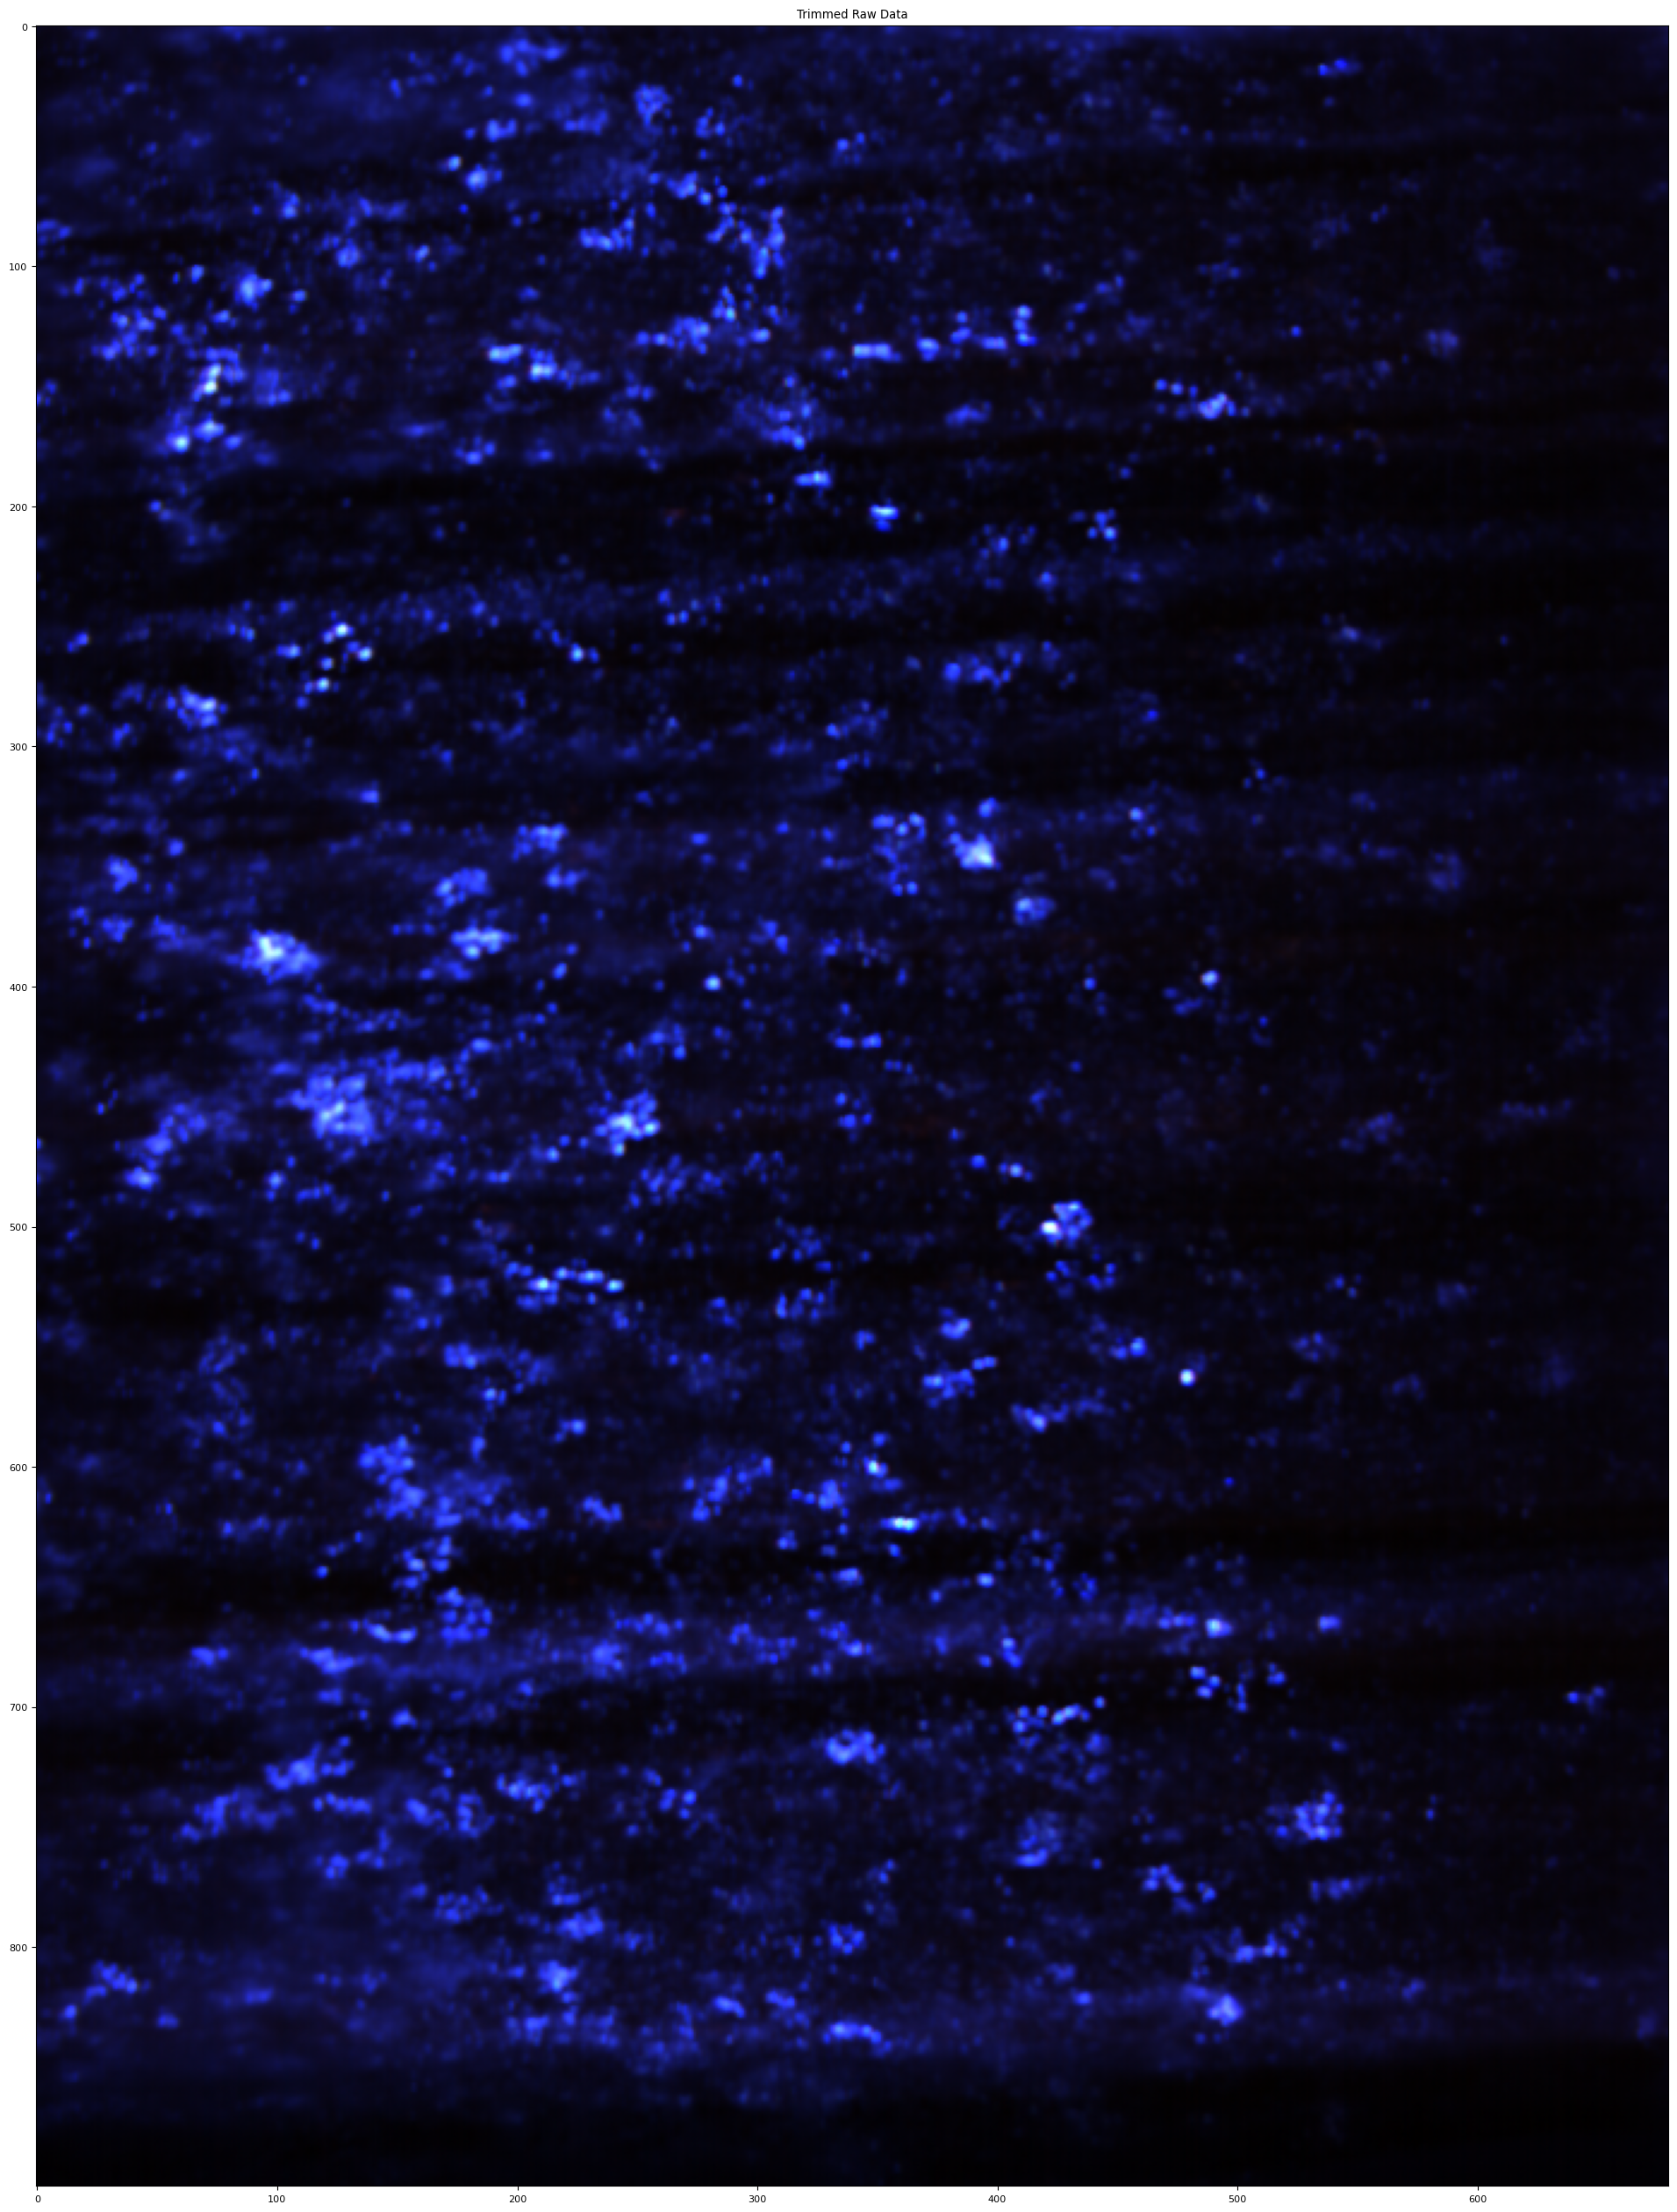

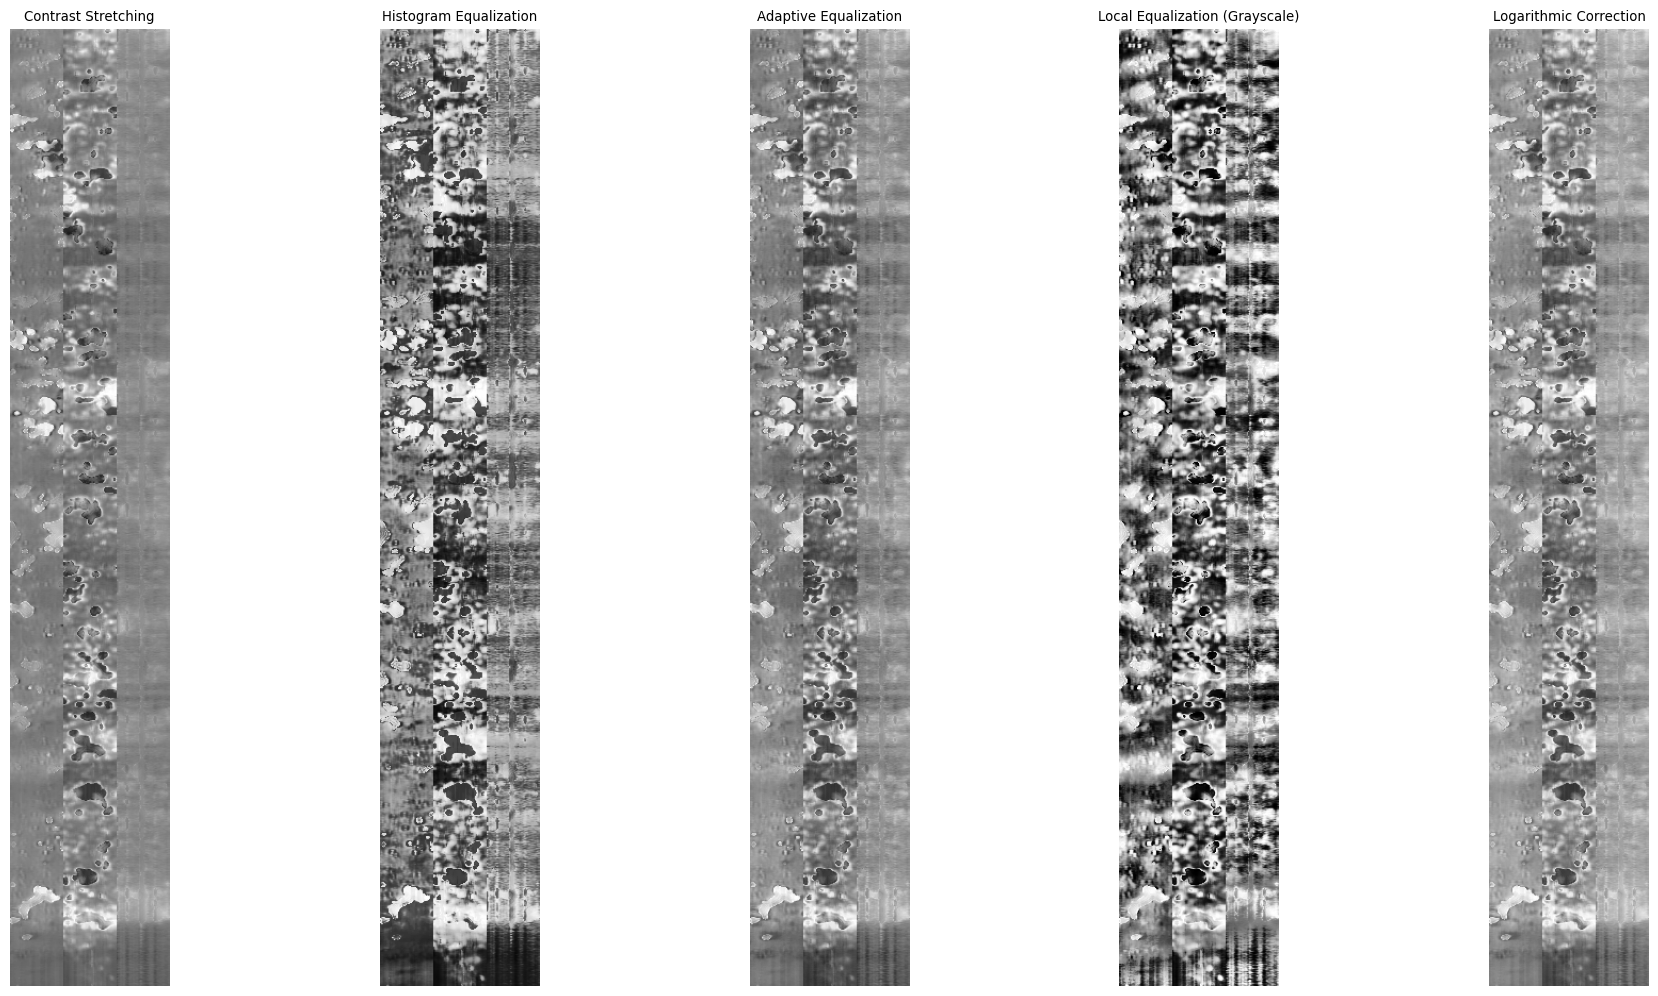

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt

trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize, Debug) #return arr of 3 trimmed
left, middle, right = processice.extract_sections(trimmedData)
left_correctedData = processice.reflectance(left, Debug)
mid_correctedData = processice.reflectance(middle, Debug)
right_correctedData = processice.reflectance(right, Debug)

left_filtered_img = processice.remove_bands(left_correctedData, trimmedData[1])
mid_filtered_img = processice.remove_bands(mid_correctedData, trimmedData[1])
right_filtered_img = processice.remove_bands(right_correctedData, trimmedData[1])

# left_previewed_img = processice.previewImg(left_filtered_img, "Filtered Image")
# previewed_img = processice.previewImg(filtered_img, "Filtered Image")
# previewed_img = processice.previewImg(filtered_img, "Filtered Image")

left_inpainted_img = processice.bubbles(left_filtered_img,  fwhm)
mid_inpainted_img = processice.bubbles(mid_filtered_img,  fwhm)
right_inpainted_img = processice.bubbles(right_filtered_img,  fwhm)

left_flattened_img = processice.flatten_data(left_inpainted_img)
mid_flattened_img = processice.flatten_data(mid_inpainted_img)
right_flattened_img = processice.flatten_data(right_inpainted_img)

left_rematrix_img = processice.resize_matrix(left_flattened_img, left, pc_num = 3) #pc_num can be changed
mid_rematrix_img = processice.resize_matrix(mid_flattened_img, middle, pc_num = 3) #pc_num can be changed
right_rematrix_img = processice.resize_matrix(right_flattened_img, right, pc_num = 3) #pc_num can be changed

rematrix_img = np.concatenate((left_rematrix_img, mid_rematrix_img, right_rematrix_img), axis=1)
eq_img = processice.equalize(rematrix_img)

# left_eq_img = processice.equalize(left_rematrix_img)
# mid_eq_img = processice.equalize(mid_rematrix_img)
# right_eq_img = processice.equalize(right_rematrix_img)

# print("left_eq_img: ",left_eq_img.shape)
# print("mid_eq_img: ",mid_eq_img.shape)
# print("right_eq_img: ",right_eq_img.shape)

# final_img = np.concatenate((left_eq_img, mid_eq_img, right_eq_img), axis=1)
# plt.close()

# from skimage.color import rgb2gray
# final_img = rgb2gray(final_img)
# plt.figure(figsize=(5, 15), dpi=150)
# plt.imshow(final_img, cmap='gray')
# plt.show()

In [6]:
# start_cm = int(top_depth * 100)
# depths_cm = np.arange(start_cm, start_cm + len(segment_boundaries))
# depth_col = "Depth"
# age_col = "Ice Age"
# header = 40
# age_df = ageConversion.map_depths_to_ages("/data/icecores/ICD/WDC06A/WD2014_26Aug2014.xlsx", depths_cm, top_depth, depth_col, age_col, header)
# print(age_df)